# Dataset Sports Car Prices

Prices of different sports cars from various manufacturers

[Kaggle dataset](https://www.kaggle.com/datasets/rkiattisak/sports-car-prices-dataset/data)


## Import Libraries

In [136]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly as pt

import os
import kagglehub
import warnings

from sklearn.metrics import (
    r2_score, mean_absolute_error, mean_squared_error
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor

## Load Dataset

In [3]:
kaggle_path = kagglehub.dataset_download("rkiattisak/sports-car-prices-dataset")

# чтобы посмотреть какие файлы лежат в папке
# print(os.listdir(kaggle_path))

df = pd.read_csv(os.path.join(kaggle_path, "Sport car price.csv"))

display(df.head())
print()
display(df.tail())

Using Colab cache for faster access to the 'sports-car-prices-dataset' dataset.


,Car Make,Car Model,Year,Engine Size (L),Horsepower,Torque (lb-ft),0-60 MPH Time (seconds),Price (in USD)
0,Porsche,911,2022,3,379,331,4,"101,200"
1,Lamborghini,Huracan,2021,5.2,630,443,2.8,"274,390"
2,Ferrari,488 GTB,2022,3.9,661,561,3,"333,750"
3,Audi,R8,2022,5.2,562,406,3.2,"142,700"
4,McLaren,720S,2021,4,710,568,2.7,"298,000"


,Car Make,Car Model,Year,Engine Size (L),Horsepower,Torque (lb-ft),0-60 MPH Time (seconds),Price (in USD)
1002,Koenigsegg,Jesko,2022,5,1280,1106,2.5,"3,000,000"
1003,Lotus,Evija,2021,Electric Motor,1972,1254,2,"2,000,000"
1004,McLaren,Senna,2021,4,789,590,2.7,"1,000,000"
1005,Pagani,Huayra,2021,6,764,738,3,"2,600,000"
1006,Rimac,Nevera,2021,Electric Motor,1888,1696,1.85,"2,400,000"


## Dataset Overview

In [4]:
print(' --- Sport car price ---')
print("*" * 50)
print(f"Dataset shape: {df.shape}")
print(df.info(), '\n')
print(df.describe().T, '\n')
print("Missing values\n", df.isna().sum())

 --- Sport car price ---
**************************************************
Dataset shape: (1007, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1007 entries, 0 to 1006
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Car Make                 1007 non-null   object
 1   Car Model                1007 non-null   object
 2   Year                     1007 non-null   int64 
 3   Engine Size (L)          997 non-null    object
 4   Horsepower               1007 non-null   object
 5   Torque (lb-ft)           1004 non-null   object
 6   0-60 MPH Time (seconds)  1007 non-null   object
 7   Price (in USD)           1007 non-null   object
dtypes: int64(1), object(7)
memory usage: 63.1+ KB
None 

       count         mean       std     min     25%     50%     75%     max
Year  1007.0  2021.201589  2.019802  1965.0  2021.0  2021.0  2022.0  2023.0 

Missing values
 Car Make                    0
Car M

In [5]:
display(df.describe(include=['object']).T)

,count,unique,top,freq
Car Make,1007,38,Porsche,88
Car Model,1007,176,GT,55
Engine Size (L),997,45,4,219
Horsepower,1007,124,503,45
Torque (lb-ft),1004,93,590,71
0-60 MPH Time (seconds),1007,43,3.5,153
Price (in USD),1007,367,"500,000",34


### Duplicates

In [8]:
print(f"Количество дубликатов: {df.duplicated().sum()}\n")

Количество дубликатов: 288



## Key Observations

- Колонки Year, Engine Size, Horsepower, 0-60 MPH Time (seconds), Price (in USD) требуют дальнейшего анализа и изменения типа данных на float | int

- Наблюдается большое кол-во дубликатов

- В качестве целевой переменной выступает Price (in USD)

## Understanding Each Feature

- Car Make - object - Компания производитель
- Car Model - object - Модель машины
- Year - int - Год выпуска машины
- Engine Size (L) - object - Объем двигателя спортивного автомобиля в литрах, который представляет собой объем цилиндров двигателя (при этом некторые автомобили имеют электродвигатели).
- Housepower - object - Лошадиная сила машины
- Torque (lb-ft) - object - Крутящий момент спортивного автомобиля в фунт-футах
- 0-60 MPH Time (seconds) - object - Время, необходимое спортивному автомобилю для разгона с 0 до 60 миль в час
- Price (in USD) - object - цена в долларах


##  Cleaning Dataset

In [9]:
df_clean = df.copy()
df_clean.head()

,Car Make,Car Model,Year,Engine Size (L),Horsepower,Torque (lb-ft),0-60 MPH Time (seconds),Price (in USD)
0,Porsche,911,2022,3,379,331,4,"101,200"
1,Lamborghini,Huracan,2021,5.2,630,443,2.8,"274,390"
2,Ferrari,488 GTB,2022,3.9,661,561,3,"333,750"
3,Audi,R8,2022,5.2,562,406,3.2,"142,700"
4,McLaren,720S,2021,4,710,568,2.7,"298,000"


### Delete duplicates

In [10]:
df_clean = df_clean.drop_duplicates()
df_clean.duplicated().sum()

print(f"Original Dataset shape: {df.shape}")
print(f"Cleaned Dataset shape: {df_clean.shape}")

Original Dataset shape: (1007, 8)
Cleaned Dataset shape: (719, 8)


### Change the column name

In [11]:
df_clean.rename(columns=lambda x: x.replace(' ', '_'), inplace=True)

### Unique values & anomalies

In [12]:
df_clean.nunique()

,0
Car_Make,38
Car_Model,176
Year,9
Engine_Size_(L),45
Horsepower,124
Torque_(lb-ft),93
0-60_MPH_Time_(seconds),43
Price_(in_USD),367


In [13]:
for col in df_clean.select_dtypes(include=['object']):
  print(df_clean[col].value_counts(), '\n')

Car_Make
Porsche          70
Audi             52
McLaren          48
Mercedes-Benz    48
Lamborghini      44
Aston Martin     39
Dodge            37
Chevrolet        37
BMW              36
Ferrari          31
Nissan           31
Lotus            24
Bentley          24
Ford             22
Jaguar           21
Maserati         19
Tesla            19
Bugatti          15
Alfa Romeo       15
Rimac            12
Pagani           11
Mercedes-AMG     10
Koenigsegg       10
Lexus             9
Rolls-Royce       9
Acura             6
Subaru            3
Toyota            3
W Motors          3
TVR               2
Pininfarina       2
Ariel             1
Mazda             1
Polestar          1
Shelby            1
Kia               1
Alpine            1
Ultima            1
Name: count, dtype: int64 

Car_Model
GT                     24
Continental GT         23
370Z Nismo             20
F-Type                 18
GranTurismo            18
                       ..
Panamera GTS            1
AMG GT 4-Do

### Change type of data

In [14]:
df_clean['Horsepower'] = pd.to_numeric(df_clean['Horsepower'].str.replace(r'[,+]', '', regex=True), errors='coerce')
df_clean['Price_(in_USD)'] = pd.to_numeric(df_clean['Price_(in_USD)'].str.replace(r'[,$]', '', regex=True), errors='coerce')
df_clean['0-60_MPH_Time_(seconds)'] = pd.to_numeric(df_clean['0-60_MPH_Time_(seconds)'].str.replace(r'[<]', '', regex=True), errors='coerce')
df_clean['Torque_(lb-ft)'] = pd.to_numeric(df_clean['Torque_(lb-ft)'].str.replace(r'[,+]', '', regex=True), errors='coerce')


In [15]:
df_clean['is_Electric'] = df_clean['Engine_Size_(L)'].str.contains('Electric', na=False).astype('int64')
df_clean['is_Hybrid'] = df_clean['Engine_Size_(L)'].str.contains('Hybrid', na=False).astype('int64')
df_clean['Engine_Size_(L)'] = df_clean['Engine_Size_(L)'].str.extract(r'(\d+\.?\d*)', expand=False).astype('float64')

In [17]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 719 entries, 0 to 1006
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Car_Make                 719 non-null    object 
 1   Car_Model                719 non-null    object 
 2   Year                     719 non-null    int64  
 3   Engine_Size_(L)          671 non-null    float64
 4   Horsepower               719 non-null    int64  
 5   Torque_(lb-ft)           715 non-null    float64
 6   0-60_MPH_Time_(seconds)  719 non-null    float64
 7   Price_(in_USD)           719 non-null    int64  
 8   is_Electric              719 non-null    int64  
 9   is_Hybrid                719 non-null    int64  
dtypes: float64(3), int64(5), object(2)
memory usage: 61.8+ KB


### Fill missing values

In [18]:
mask_electric_like = df_clean['is_Electric'] & df_clean['Engine_Size_(L)'].isna()
mask_electric_like

,0
0,False
1,False
2,False
3,False
4,False
...,...
999,False
1002,False
1003,True
1005,False


In [19]:
# Для чистых электро и Electric Motor объём ДВС = 0
mask_electric_like = df_clean['is_Electric'] & df_clean['Engine_Size_(L)'].isna()
df_clean.loc[mask_electric_like, 'Engine_Size_(L)'] = 0.0

# Для гибридов без указания объёма можно взять медиану по всем гибридам
hybrid_median = df_clean.loc[df_clean['is_Hybrid'] & df_clean['Engine_Size_(L)'].notna(), 'Engine_Size_(L)'].median()
df_clean.loc[df_clean['is_Hybrid'] & df_clean['Engine_Size_(L)'].isna(), 'Engine_Size_(L)'] = hybrid_median

# Оставшиеся NaN реальные пропуски, заполняем медианой всей колонки
df_clean['Engine_Size_(L)'] = df_clean['Engine_Size_(L)'].fillna(df_clean['Engine_Size_(L)'].median())

In [20]:
df_clean['Torque_(lb-ft)'] = df_clean['Torque_(lb-ft)'].fillna(df_clean['Torque_(lb-ft)'].median())

## Numerical Variables: Distribution & Skewness

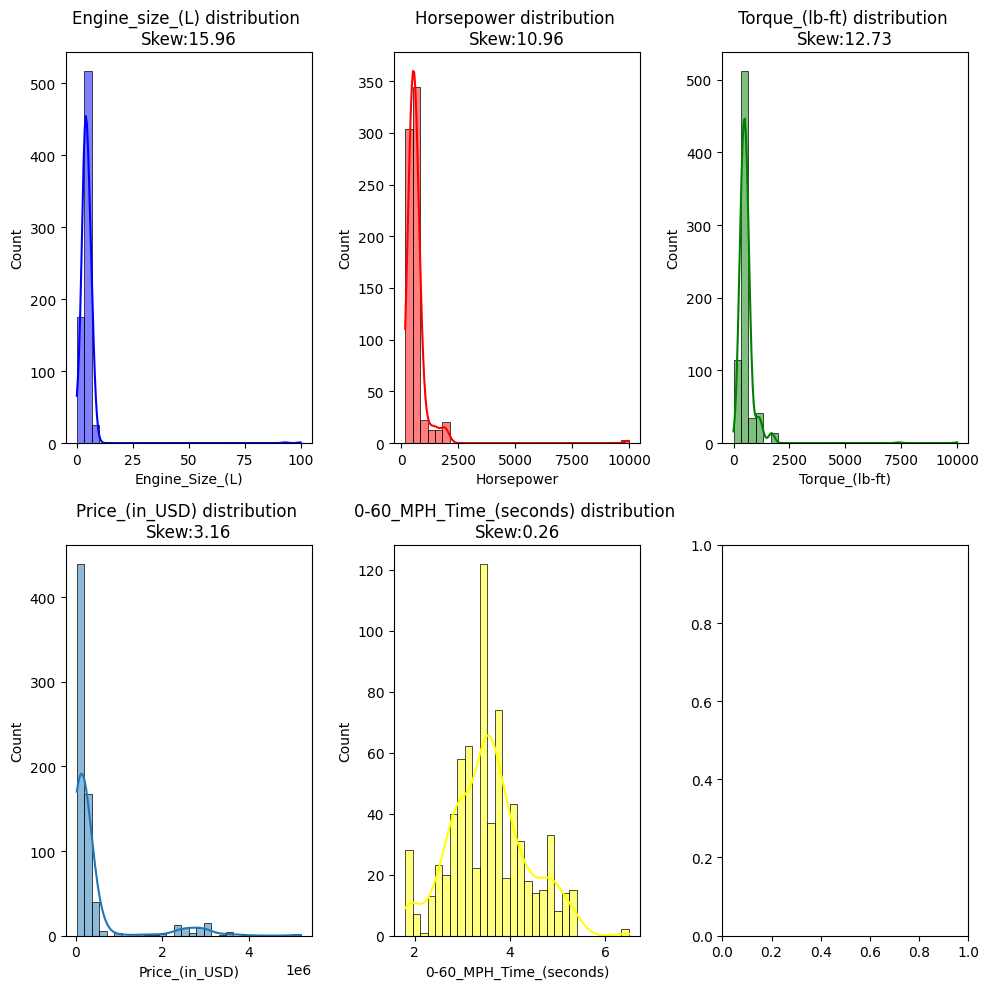

In [44]:
fig, axes = plt.subplots(2, 3, figsize=(10, 10))

# Engine size distribution
sns.histplot(data=df_clean['Engine_Size_(L)'], kde=True, bins=30, color='b', ax=axes[0][0])
axes[0][0].set_title(f'Engine_size_(L) distribution \nSkew:{df_clean['Engine_Size_(L)'].skew():.2f}')

# Horsepower distribution
sns.histplot(data=df_clean['Horsepower'], kde=True, bins=30, color='r', ax=axes[0][1])
axes[0][1].set_title(f'Horsepower distribution \nSkew:{df_clean['Horsepower'].skew():.2f}')

#Torque_(lb-ft) distribution
sns.histplot(data=df_clean['Torque_(lb-ft)'], kde=True, bins=30, color='g', ax=axes[0][2])
axes[0][2].set_title(f'Torque_(lb-ft) distribution \nSkew:{df_clean['Torque_(lb-ft)'].skew():.2f}')

#Price_(in_USD) distributon
sns.histplot(data=df_clean['Price_(in_USD)'], kde=True, bins=30, ax=axes[1][0])
axes[1][0].set_title(f'Price_(in_USD) distribution \nSkew:{df_clean['Price_(in_USD)'].skew():.2f}')

#0-60_MPH_Time_(seconds) distribution
sns.histplot(data=df_clean['0-60_MPH_Time_(seconds)'], kde=True, bins=30, color='yellow', ax=axes[1][1])
axes[1][1].set_title(f'0-60_MPH_Time_(seconds) distribution \nSkew:{df_clean['0-60_MPH_Time_(seconds)'].skew():.2f}')

plt.tight_layout()
plt.show()

Key Findings

- Большинство признаков имеют правостороннюю асимметрию.

- Признак 0-60_MPH_Time_(seconds) имеет распределение с небольшой асимметрией в 0.26 (близок к нормальному распределению)

- Гистограмма признака Engine_size_(L) отображает, что у большинства спортивных машин  рабочий объём двигателя внутреннего сгорания (ДВС) находится в диапозоне от 4 до приблизительно 6. Также можно визуально сравнить кол-во спортивных машин с элетро двигателем (ДВС = 0) с остальными спортивными машинами

- Гистограмма признака Horsepower говорит о том, что основная масса машин до 2000 л.с., но есть редкие машины с мощностью около 8000-10000 л.с.

- Имеется явное подозрение на ошибку в выбросе данных по признаку Engine_size_(L), ведь машины с ДВС около 100 литров не существуют.

- Гистограмма признака Price_(in USD): основная масса машин стоит в районе 500 000 - 1 000 000 долларов, но есть несколько спортивных машин за 2-4 миллионов.

In [77]:
incorrect_data = df_clean[df_clean['Engine_Size_(L)'] > 9].index.tolist()
df_clean.drop(index=incorrect_data, inplace=True)

## Box Plots & Outlier Assessment

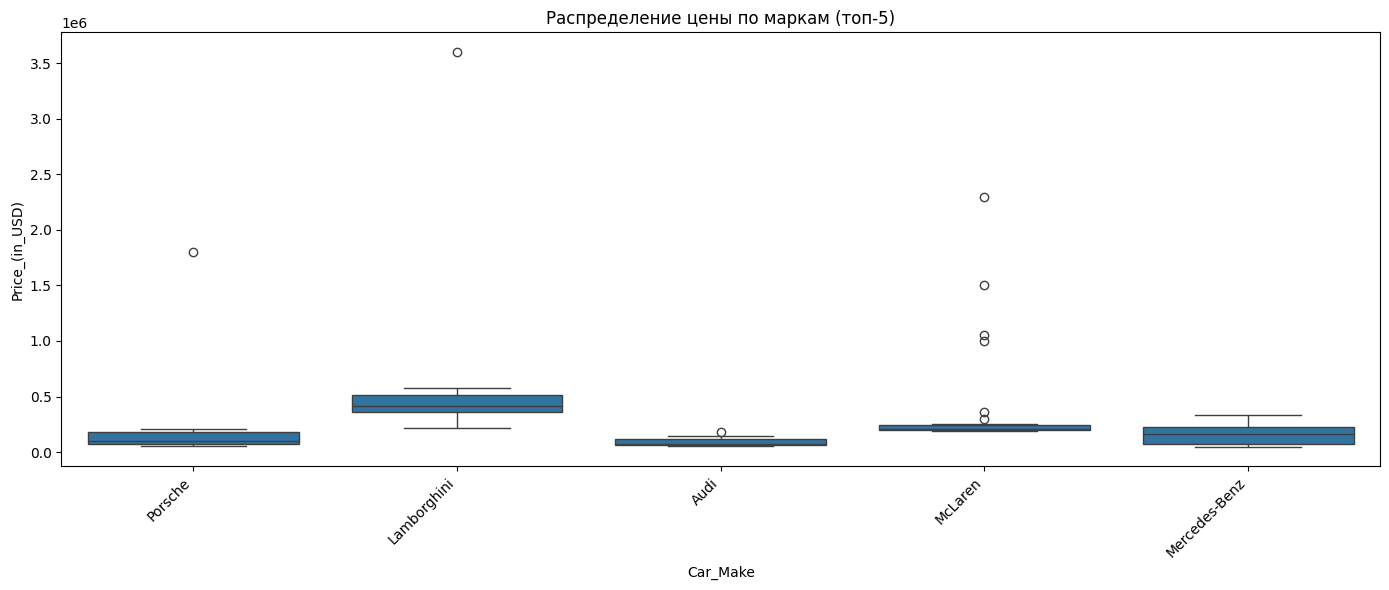

In [78]:
top_makes = df_clean['Car_Make'].value_counts().head(5).index

plt.figure(figsize=(14, 6))
sns.boxplot(data=df_clean[df_clean['Car_Make'].isin(top_makes)],
            x='Car_Make', y='Price_(in_USD)')
plt.xticks(rotation=45, ha='right')
plt.title('Распределение цены по маркам (топ-5)')
plt.tight_layout()
plt.show()

In [79]:
def detect_iqr_outliers(data, column):
  q1 = data[column].quantile(0.25)
  q3 = data[column].quantile(0.75)
  iqr = q3 - q1
  lower_bound = q1 - 1.5*iqr
  upper_bound = q3 + 1.5*iqr
  outliers = data[(data[column] < lower_bound) | (data[column] > upper_bound)]
  print(f'=== {column} === Outlier Analysis')
  print(f"Q1 : {q1:.2f} Q3 : {q3:.2f} Upper bound {upper_bound:.2f} Lower bound {lower_bound:.2f}")
  print(f"Outliers : {len(outliers)}, percentage:{len(outliers) / len(data) * 100:.2f}%")
  print(f"Min Outlier: {outliers[column].min()} Max Outlier {outliers[column].max()}")

for col in ['Engine_Size_(L)', 'Horsepower','Torque_(lb-ft)', '0-60_MPH_Time_(seconds)','Price_(in_USD)']:
  detect_iqr_outliers(df_clean.dropna(subset=[col]), col)


=== Engine_Size_(L) === Outlier Analysis
Q1 : 3.50 Q3 : 5.20 Upper bound 7.75 Lower bound 0.95
Outliers : 54, percentage:7.53%
Min Outlier: 0.0 Max Outlier 8.4
=== Horsepower === Outlier Analysis
Q1 : 454.00 Q3 : 710.00 Upper bound 1094.00 Lower bound 70.00
Outliers : 49, percentage:6.83%
Min Outlier: 1200 Max Outlier 10000
=== Torque_(lb-ft) === Outlier Analysis
Q1 : 400.00 Q3 : 627.00 Upper bound 967.50 Lower bound 59.50
Outliers : 58, percentage:8.09%
Min Outlier: 0.0 Max Outlier 10000.0
=== 0-60_MPH_Time_(seconds) === Outlier Analysis
Q1 : 3.00 Q3 : 4.00 Upper bound 5.50 Lower bound 1.50
Outliers : 2, percentage:0.28%
Min Outlier: 6.4 Max Outlier 6.5
=== Price_(in_USD) === Outlier Analysis
Q1 : 70100.00 Q3 : 225000.00 Upper bound 457350.00 Lower bound -162250.00
Outliers : 94, percentage:13.11%
Min Outlier: 460247 Max Outlier 5200000


Key Findings

- Lamborghini самый дорогой бренд в медиане. Ящик (межквартильный размах) расположен выше всех,  (нет выбросов)

- Porsche и Audi близки по медиане. Это массовые премиум-бренды, где большинство моделей стоит относительно недорого для этого сегмента.

- Mercedes-Benz  медиана чуть выше. McLaren   ящик очень узкий, но огромное количество выбросов вверх.

- Имеется много выбросов, что может сильно повлиять на обучении линейных моделей.


## Heatmap

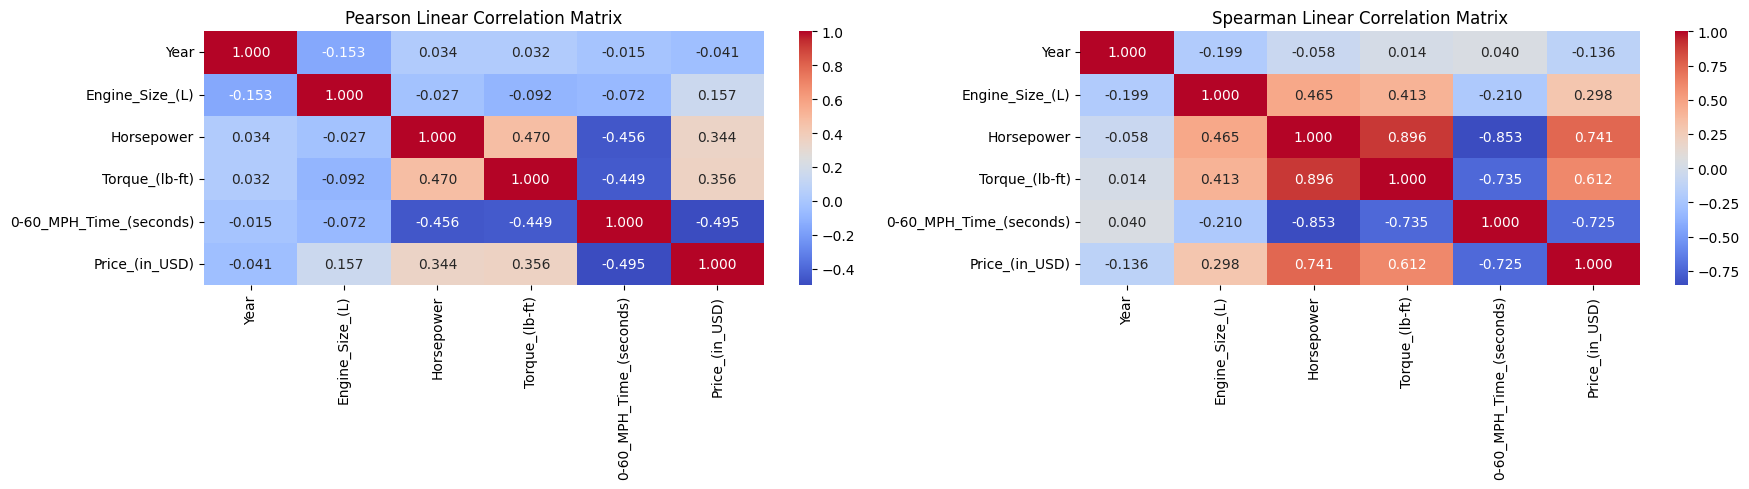

In [83]:
# numeric_cols = ['Year', 'Engine_Size_(L)', 'Horsepower', 'Torque_(lb-ft)', '0-60_MPH_Time_(seconds)', 'Price_(in_USD)', 'is_Electric', 'is_Hybrid']
numeric_cols = ['Year', 'Engine_Size_(L)', 'Horsepower', 'Torque_(lb-ft)', '0-60_MPH_Time_(seconds)', 'Price_(in_USD)']

corr_pearson = df_clean[numeric_cols].corr(method='pearson')
corr_spearman = df_clean[numeric_cols].corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(18, 5))

sns.heatmap(corr_pearson, annot=True, fmt='.3f', cmap='coolwarm', ax=axes[0])
axes[0].set_title('Pearson Linear Correlation Matrix')

sns.heatmap(corr_spearman, annot=True, fmt='.3f', cmap='coolwarm', ax=axes[1])
axes[1].set_title('Spearman Correlation Matrix')

plt.tight_layout()
plt.show()

Key Findings

- Корреляционная матрица по методу Spearman показывает более достоверные данные из-за устойчивости к выбросам, нежели линейный Pearson

- Между Price_(in_USD) и Horsepower наблюдается сильная положительная корреляция 0.741 (чем больше Horsepower, тем выше Цена)

- Между Price_(in_USD) и Torque_(lb-ft) наблюдается сильная положительная корреляция 0.896 (чем больше Torque_(lb-ft), тем выше Цена) Ввиду корреляции 0.896, признаки Horsepower и Torque избыточны. Для линейных моделей один из них (например, Torque) можно удалить, чтобы избежать мультиколлинеарности.

- Между Price_(in_USD) и 0-60_MPH_Time_(seconds) наблюдается сильная отрицательная корреляция (чем больше 0-60_MPH_Time_(seconds), тем ниже Цена)

- Между Price_(in_USD) и Engine_Size_(L) наблюдается слабая положительная корреляция

- Между Horsepower и Torque_(lb-ft) наблюдается сильная положительная корреляция (чем больше Horsepower, тем выше Torque_(lb-ft))

- Наблюдается слабая положительная корреляция у Engine_size_(L) с Horsepower, Torque_(lb-ft) Это указывает на то, что объем двигателя не является определяющим фактором

- Корреляция Year с Engine_Size (-0.20) указывает на тенденцию к уменьшению объема двигателей с годами выпуска.

## Data Preparation & Preprocessing

In [91]:
display(df_clean.head())

df_clean.info()

,Car_Make,Car_Model,Year,Engine_Size_(L),Horsepower,Torque_(lb-ft),0-60_MPH_Time_(seconds),Price_(in_USD),is_Electric,is_Hybrid
0,Porsche,911,2022,3.0,379,331.0,4.0,101200,0,0
1,Lamborghini,Huracan,2021,5.2,630,443.0,2.8,274390,0,0
2,Ferrari,488 GTB,2022,3.9,661,561.0,3.0,333750,0,0
3,Audi,R8,2022,5.2,562,406.0,3.2,142700,0,0
4,McLaren,720S,2021,4.0,710,568.0,2.7,298000,0,0


<class 'pandas.core.frame.DataFrame'>
Index: 717 entries, 0 to 1006
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Car_Make                 717 non-null    object 
 1   Car_Model                717 non-null    object 
 2   Year                     717 non-null    int64  
 3   Engine_Size_(L)          717 non-null    float64
 4   Horsepower               717 non-null    int64  
 5   Torque_(lb-ft)           717 non-null    float64
 6   0-60_MPH_Time_(seconds)  717 non-null    float64
 7   Price_(in_USD)           717 non-null    int64  
 8   is_Electric              717 non-null    int64  
 9   is_Hybrid                717 non-null    int64  
dtypes: float64(3), int64(5), object(2)
memory usage: 61.6+ KB


### Encoding (One-Hot Encoding)

In [103]:
df_encoded = df_clean.copy()

df_encoded = df_encoded.drop(columns=['Car_Model'])
df_encoded = pd.get_dummies(df_encoded, drop_first=True)
df_encoded.iloc[:, 6:] = df_encoded.iloc[:, 6:].astype('int64')

df_encoded.head()

/tmp/ipykernel_2424/3863588932.py:5: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '0       0
1       0
2       0
3       0
4       0
       ..
999     0
1002    0
1003    0
1005    0
1006    0
Name: Car_Make_Alfa Romeo, Length: 717, dtype: int64' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  df_encoded.iloc[:, 6:] = df_encoded.iloc[:, 6:].astype('int64')
/tmp/ipykernel_2424/3863588932.py:5: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '0       0
1       0
2       0
3       0
4       0
       ..
999     0
1002    0
1003    0
1005    0
1006    0
Name: Car_Make_Alpine, Length: 717, dtype: int64' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  df_encoded.iloc[:, 6:] = df_encoded.iloc[:, 6:].astype('int64')
/tmp/ipykernel_2424/3863588932.py:5: FutureWarning: Setting an

,Year,Engine_Size_(L),Horsepower,Torque_(lb-ft),0-60_MPH_Time_(seconds),Price_(in_USD),is_Electric,is_Hybrid,Car_Make_Alfa Romeo,Car_Make_Alpine,...,Car_Make_Porsche,Car_Make_Rimac,Car_Make_Rolls-Royce,Car_Make_Shelby,Car_Make_Subaru,Car_Make_TVR,Car_Make_Tesla,Car_Make_Toyota,Car_Make_Ultima,Car_Make_W Motors
0,2022,3.0,379,331.0,4.0,101200,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
1,2021,5.2,630,443.0,2.8,274390,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2022,3.9,661,561.0,3.0,333750,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,2022,5.2,562,406.0,3.2,142700,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2021,4.0,710,568.0,2.7,298000,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


###  Defining Features and Target

In [104]:
X = df_encoded.drop(columns='Price_(in_USD)')
y = df_encoded['Price_(in_USD)']

### Stratified Train-Test Split & Feature Scaling

In [109]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=15,
)

print(f"Training set: X_train = {X_train.shape}, y_train = {y_train.shape}")
print(f"Test set:     X_test  = {X_test.shape}, y_test  = {y_test.shape}")

# Feature Scaling

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

Training set: X_train = (573, 44), y_train = (573,)
Test set:     X_test  = (144, 44), y_test  = (144,)


In [137]:
# Логарифмируем таргет (Price сильно право-асимметричен)
y_train_log = np.log1p(y_train)
y_test_log  = np.log1p(y_test)

# Для деревьев — сырые данные (без масштабирования)
X_train_raw = X_train
X_test_raw  = X_test

models = {}
predictions = {}

# Baseline Linear Regression (без регуляризации)
m1 = LinearRegression()
m1.fit(X_train_scaled, y_train_log)
models['Linear Regression'] = m1
predictions['Linear Regression'] = np.expm1(m1.predict(X_test_scaled))

# Ridge
m2 = Ridge(alpha=1.0, random_state=15)
m2.fit(X_train_scaled, y_train_log)
models['Ridge Regression'] = m2
predictions['Ridge Regression'] = np.expm1(m2.predict(X_test_scaled))

# Random Forest Regressor
m3 = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=3,
    random_state=15
)
m3.fit(X_train_raw, y_train_log)
models['Random Forest'] = m3
predictions['Random Forest'] = np.expm1(m3.predict(X_test_raw))

# Model Evaluation
results = []
for name, y_pred in predictions.items():
    mae  = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2   = r2_score(y_test, y_pred)

    results.append({
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'R^2': r2,
    })

results_df = pd.DataFrame(results).set_index('Model').round(4)
print("\nСравнение моделей:")
display(results_df)


Сравнение моделей:


,MAE,RMSE,R^2
Model,,,
Linear Regression,110643.8341,352607.3912,0.8402
Ridge Regression,110707.2381,353209.9471,0.8397
Random Forest,104994.5976,364027.2373,0.8297


In [139]:
# График Предсказание VS Реальность

fig = make_subplots(
    rows=1, cols=3,
    subplot_titles=list(predictions.keys()),
    horizontal_spacing=0.08
)

# Общий диапазон для осей (чтобы все панели были в одной шкале)
all_vals = np.concatenate([y_test.values] + [p for p in predictions.values()])
lim_min, lim_max = all_vals.min(), all_vals.max()

for i, (name, y_pred) in enumerate(predictions.items(), start=1):
    r2  = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)

    # 1. Точки
    fig.add_trace(
        go.Scatter(
            x=y_test, y=y_pred, mode='markers', name=name,
            marker=dict(size=6, color='steelblue', opacity=0.6,
                        line=dict(width=0.5, color='white')),
            hovertemplate=(
                '<b>Реальная цена:</b> $%{x:,.0f}<br>'
                '<b>Предсказанная:</b> $%{y:,.0f}<br>'
                '<b>Ошибка:</b> $%{customdata:,.0f}<extra></extra>'
            ),
            customdata=np.abs(y_test - y_pred),
            showlegend=False
        ),
        row=1, col=i
    )

    # 2. Идеал
    fig.add_trace(
        go.Scatter(
            x=[lim_min, lim_max], y=[lim_min, lim_max],
            mode='lines', name='Идеал (y = x)',
            line=dict(color='red', width=2, dash='dash'),
            hoverinfo='skip', showlegend=(i == 1)
        ),
        row=1, col=i
    )

    # 3. Тренд модели
    z = np.polyfit(y_test, y_pred, 1)
    p = np.poly1d(z)
    xs = np.linspace(y_test.min(), y_test.max(), 100)
    fig.add_trace(
        go.Scatter(
            x=xs, y=p(xs), mode='lines', name='Тренд модели',
            line=dict(color='orange', width=2),
            hoverinfo='skip', showlegend=(i == 1)
        ),
        row=1, col=i
    )

    # 4. Плашка с метриками
    xref = 'x domain' if i == 1 else f'x{i} domain'
    yref = 'y domain' if i == 1 else f'y{i} domain'
    fig.add_annotation(
        text=f"R² = {r2:.3f}<br>MAE = ${mae:,.0f}",
        xref=xref, yref=yref,
        x=0.05, y=0.95,
        showarrow=False,
        bgcolor='white', bordercolor='gray', borderwidth=1,
        font=dict(size=12), align='left'
    )
# Оформление осей
fig.update_xaxes(title_text='Реальная цена ($)', tickformat='$,.0f', row=1, col=1)
fig.update_yaxes(title_text='Предсказанная цена ($)', tickformat='$,.0f', row=1, col=1)
for i in range(1, 4):
    fig.update_xaxes(range=[lim_min, lim_max], tickformat='$,.2s', row=1, col=i)
    fig.update_yaxes(range=[lim_min, lim_max], tickformat='$,.2s', row=1, col=i)

fig.update_layout(
    title=dict(
        text='<b>Предсказание vs Реальность: сравнение моделей</b>',
        x=0.5, xanchor='center', font=dict(size=16)
    ),
    height=550, width=1500,
    template='plotly_white',
    legend=dict(orientation='h', yanchor='bottom', y=1.08,
                xanchor='center', x=0.5)
)

fig.show()

Вывод:

- Linear Regression лучший по R^2 и RMSE, простая, быстрая и интерпретируемая, остальные модели показали +- такие же оценки.

- Огромный разрыв между MAE (около 110к) и RMSE (около 350к) у всех моделей. Это значит, что модели отлично предсказывают обычные машины (например Audi, Porsche и т.д.), но ошибаются на очень дорогих спорткарах (например Lamborghini). Модели просто не хватает данных, чтобы выучить такие цены.